In [2]:
from transformers import BertForQuestionAnswering, BertTokenizer
import torch

In [3]:
model = BertForQuestionAnswering.from_pretrained("bert-large-uncased-whole-word-masking-finetuned-squad")
tokenizer = BertTokenizer.from_pretrained("bert-large-uncased-whole-word-masking-finetuned-squad")

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:  53%|#####3    | 713M/1.34G [00:00<?, ?B/s]

Some weights of the model checkpoint at bert-large-uncased-whole-word-masking-finetuned-squad were not used when initializing BertForQuestionAnswering: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing BertForQuestionAnswering from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForQuestionAnswering from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [4]:
answer_document = "The first DVD (Digital Versatile Disc) was released on March 24, 1997. It was a movie titled 'Twister' and was released in Japan. DVDs quickly gained popularity as a replacement for VHS tapes and became a common format for storing and distributing digital video and data."
question = "What quickly gained popularity as a replacement for VHS tapes?"

In [5]:
encoding = tokenizer.encode_plus(text=question, text_pair=answer_document)

In [6]:
print(encoding)

{'input_ids': [101, 2054, 2855, 4227, 6217, 2004, 1037, 6110, 2005, 17550, 13324, 1029, 102, 1996, 2034, 4966, 1006, 3617, 22979, 5860, 1007, 2001, 2207, 2006, 2233, 2484, 1010, 2722, 1012, 2009, 2001, 1037, 3185, 4159, 1005, 9792, 2121, 1005, 1998, 2001, 2207, 1999, 2900, 1012, 22477, 2855, 4227, 6217, 2004, 1037, 6110, 2005, 17550, 13324, 1998, 2150, 1037, 2691, 4289, 2005, 23977, 1998, 20083, 3617, 2678, 1998, 2951, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [8]:
inputs = encoding['input_ids']
sentence_ids = encoding['token_type_ids']
tokens = tokenizer.convert_ids_to_tokens(inputs)

In [9]:
output = model(input_ids = torch.tensor([inputs]), token_type_ids = torch.tensor([sentence_ids]))

In [11]:
start_index = torch.argmax(output.start_logits)
end_index = torch.argmax(output.end_logits)
print(start_index)
print(end_index)

tensor(44)
tensor(44)


In [13]:
response = ' '.join(tokens[start_index:end_index+1])
print(response)

dvds


In [14]:
s_scores = output.start_logits.detach().numpy().flatten()
e_scores = output.end_logits.detach().numpy().flatten()

In [15]:
token_labels = []
for (i, token) in enumerate(tokens):
    token_labels.append('{:} - {:>4}'.format(token, i))

In [16]:
import matplotlib as plt
import seaborn as sns

C:\Users\Rudra\AppData\Local\Temp\ipykernel_34364\1329071863.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  splot.set_xticklabels(splot.get_xticklabels(), rotation=90, ha='center')


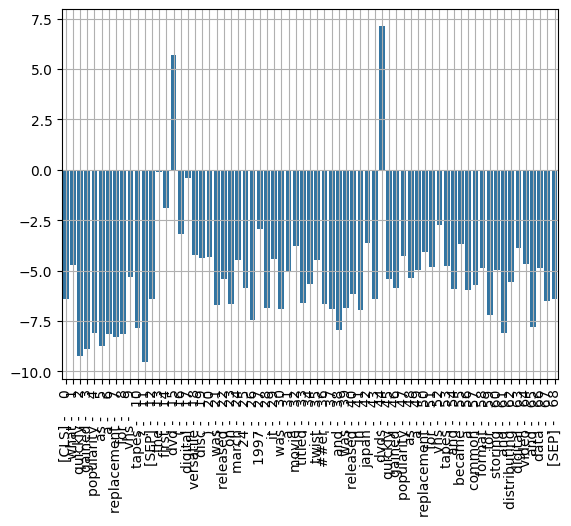

In [20]:
splot = sns.barplot(x=token_labels, y=s_scores)
splot.set_xticklabels(splot.get_xticklabels(), rotation=90, ha='center')
splot.grid(True)

In [33]:
def faq(question, context):
    inputs = tokenizer.encode(question, context)
    tokens = tokenizer.convert_ids_to_tokens(inputs)
    sep_idx = inputs.index(tokenizer.sep_token_id)
    num_seg_a = sep_idx + 1
    num_seg_b = len(inputs) - num_seg_a
    segment_ids = [0]*num_seg_a + [1]*num_seg_b
    output = model(input_ids = torch.tensor([inputs]), token_type_ids = torch.tensor([segment_ids]))
    ans_start = torch.argmax(output.start_logits)
    ans_end = torch.argmax(output.end_logits)
    if ans_end >= ans_start:
        answer = ' '.join(tokens[ans_start:ans_end+1])
    else:
        print("Can't answer, ask different question....")
    corrected_ans = ''
    for word in answer.split():
        if word[0:2] == '##':
            corrected_ans += word[2:]
        else:
            corrected_ans += ' ' + word
    return corrected_ans

In [34]:
context = "I created your TSDW Sports Working Committee interview resume based on the attached resume's two-page structure, typography, section style, horizontal rules, and overall layout.I specifically adapted the content toward sports, volunteering, event coordination, teamwork, leadership, and your future MBA profile, while retaining relevant technical/project experience."
print(context)

I created your TSDW Sports Working Committee interview resume based on the attached resume's two-page structure, typography, section style, horizontal rules, and overall layout.I specifically adapted the content toward sports, volunteering, event coordination, teamwork, leadership, and your future MBA profile, while retaining relevant technical/project experience.


In [35]:
question = "Which specific skills did I adapt?"

In [36]:
faq(question, context)

' sports , volunteering , event coordination , teamwork , leadership'

In [38]:
question1 = "What resume did I create?"

In [39]:
faq(question1, context)

' tsdw sports working committee'